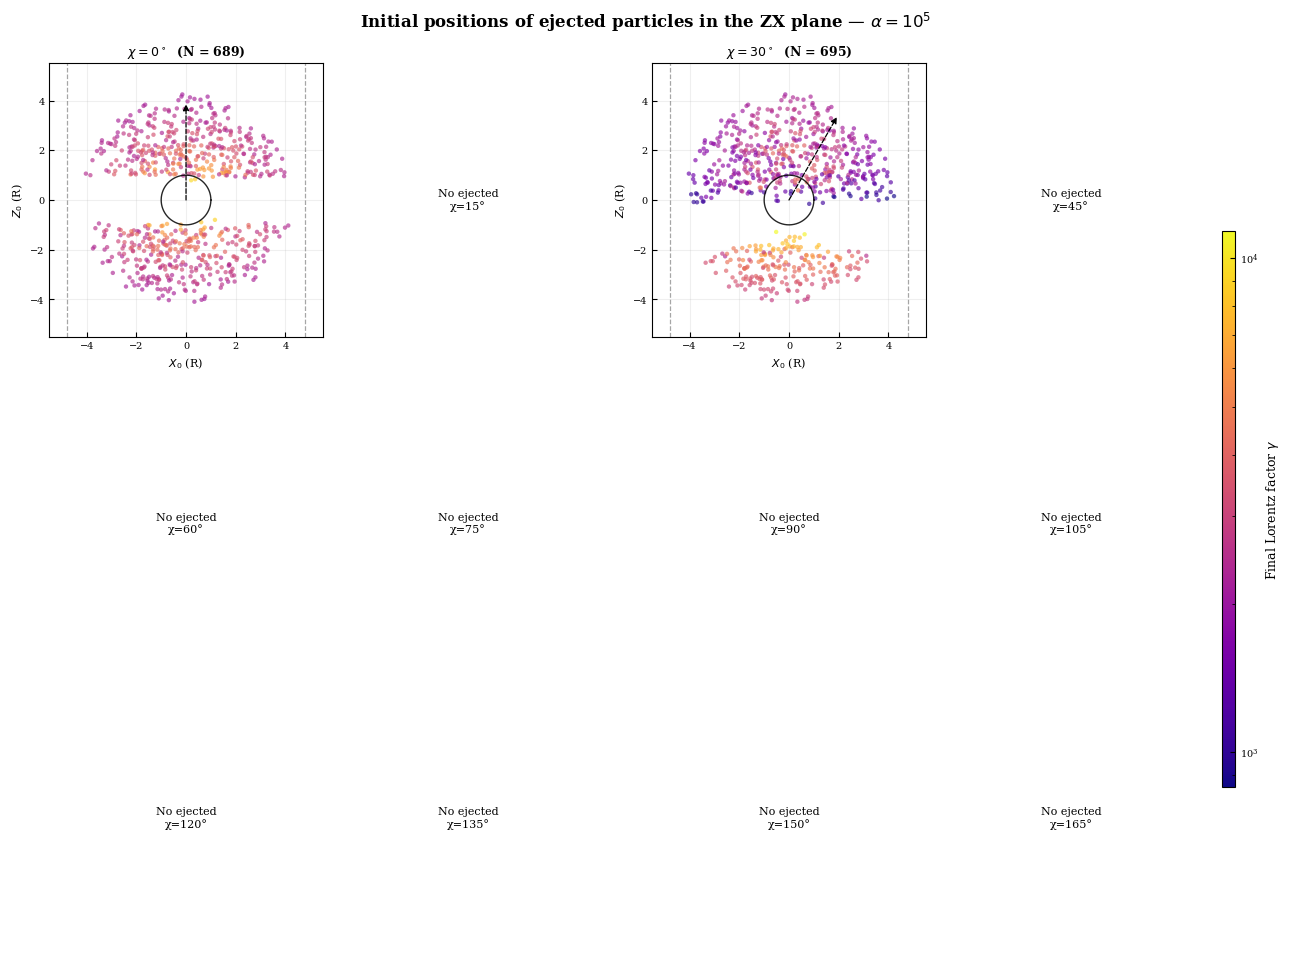

In [ ]:
# ==========================================
# GRADE 3×4 — PROJEÇÃO ZX A PARTIR DO CSV
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import FancyArrowPatch
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 8,
    'font.family': 'serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
})

# ==========================================
# CONFIGURAÇÃO
# ==========================================
CSV_FILE  = "particles_all_runs.csv"
ALPHA_VAL = 10000
ANGLES = [0, 15, 30, 45, 60, 75,
          90, 105, 120, 135, 150, 165]

POINT_SIZE   = 10
POINT_ALPHA  = 0.65
CMAP         = 'plasma'
MARKER_EDGE  = 'none'

om = 0.209
r_lc_val = 1.0 / om

# ==========================================
# CARREGA CSV
# ==========================================
df = pd.read_csv(CSV_FILE)

# Filtra alpha
df_alpha = df[df.alpha == ALPHA_VAL]

# ==========================================
# LAYOUT 3×4
# ==========================================
N_ROWS = 3
N_COLS = 4

fig, axes = plt.subplots(N_ROWS, N_COLS,
                          figsize=(3.2 * N_COLS, 3.2 * N_ROWS),
                          constrained_layout=True)
axes = axes.ravel()

theta_circ = np.linspace(0, 2*np.pi, 400)
ZOOM_LIM = r_lc_val * 1.15

# Limites globais de gamma (para colorbar consistente)
d_all = df_alpha[df_alpha.status == "Ejected"]
if len(d_all):
    vmin = max(d_all.gamma_final.min(), 1.0)
    vmax = max(d_all.gamma_final.max(), vmin * 1.001)
else:
    vmin, vmax = 1.0, 1000.0

for idx, ang in enumerate(ANGLES):
    ax = axes[idx]

    d = df_alpha[(df_alpha.angle_deg == ang) &
                 (df_alpha.status == "Ejected")]

    if len(d) == 0:
        ax.text(0.5, 0.5, f"No ejected\nχ={ang}°",
                ha='center', va='center', transform=ax.transAxes,
                fontsize=8)
        ax.set_axis_off()
        continue

    x0    = d.x0.values
    z0    = d.z0.values
    gamas = d.gamma_final.values
    N = len(gamas)

    # Scatter em ZX
    ax.scatter(x0, z0, c=gamas, cmap=CMAP,
               norm=LogNorm(vmin=vmin, vmax=vmax),
               s=POINT_SIZE, alpha=POINT_ALPHA,
               edgecolors=MARKER_EDGE, linewidths=0, zorder=3)

    # Estrela
    ax.plot(np.cos(theta_circ), np.sin(theta_circ),
            color='black', lw=1.0, alpha=0.85, zorder=4)

    # Light cylinder — retas verticais em ZX
    ax.axvline( r_lc_val, color='gray', ls='--', lw=0.9,
               alpha=0.7, zorder=2)
    ax.axvline(-r_lc_val, color='gray', ls='--', lw=0.9,
               alpha=0.7, zorder=2)

    # Seta do dipolo (direção (sin χ, cos χ) em ZX)
    chi_rad = np.radians(ang)
    L_dip = ZOOM_LIM * 0.7
    dx = np.sin(chi_rad) * L_dip
    dz = np.cos(chi_rad) * L_dip

    arrow = FancyArrowPatch(
        (0, 0), (dx, dz),
        arrowstyle='-|>', color='black',
        lw=0.9, linestyle='--', mutation_scale=9,
        shrinkA=0, shrinkB=0, zorder=5,
    )
    ax.add_patch(arrow)

    # Estética
    ax.set_xlabel(r'$X_0$ (R)', fontsize=8)
    ax.set_ylabel(r'$Z_0$ (R)', fontsize=8)
    ax.set_title(rf'$\chi = {ang}^\circ$  (N = {N})',
                 fontweight='bold', fontsize=9)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.2, zorder=0)
    ax.set_xlim(-ZOOM_LIM, ZOOM_LIM)
    ax.set_ylim(-ZOOM_LIM, ZOOM_LIM)
    ax.tick_params(labelsize=7)

# Colorbar
sm = plt.cm.ScalarMappable(cmap=CMAP,
                           norm=LogNorm(vmin=vmin, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.tolist(), location='right',
                    fraction=0.012, pad=0.012, aspect=40)
cbar.set_label(r'Final Lorentz factor $\gamma$', fontsize=9)

fig.suptitle(r'Initial positions of ejected particles in the ZX plane — '
             rf'$\alpha = 10^{{{int(np.log10(ALPHA_VAL))}}}$',
             fontsize=12, fontweight='bold')

plt.savefig('initial_positions.pdf',
            dpi=300, bbox_inches='tight', pad_inches=0.05)

plt.show()

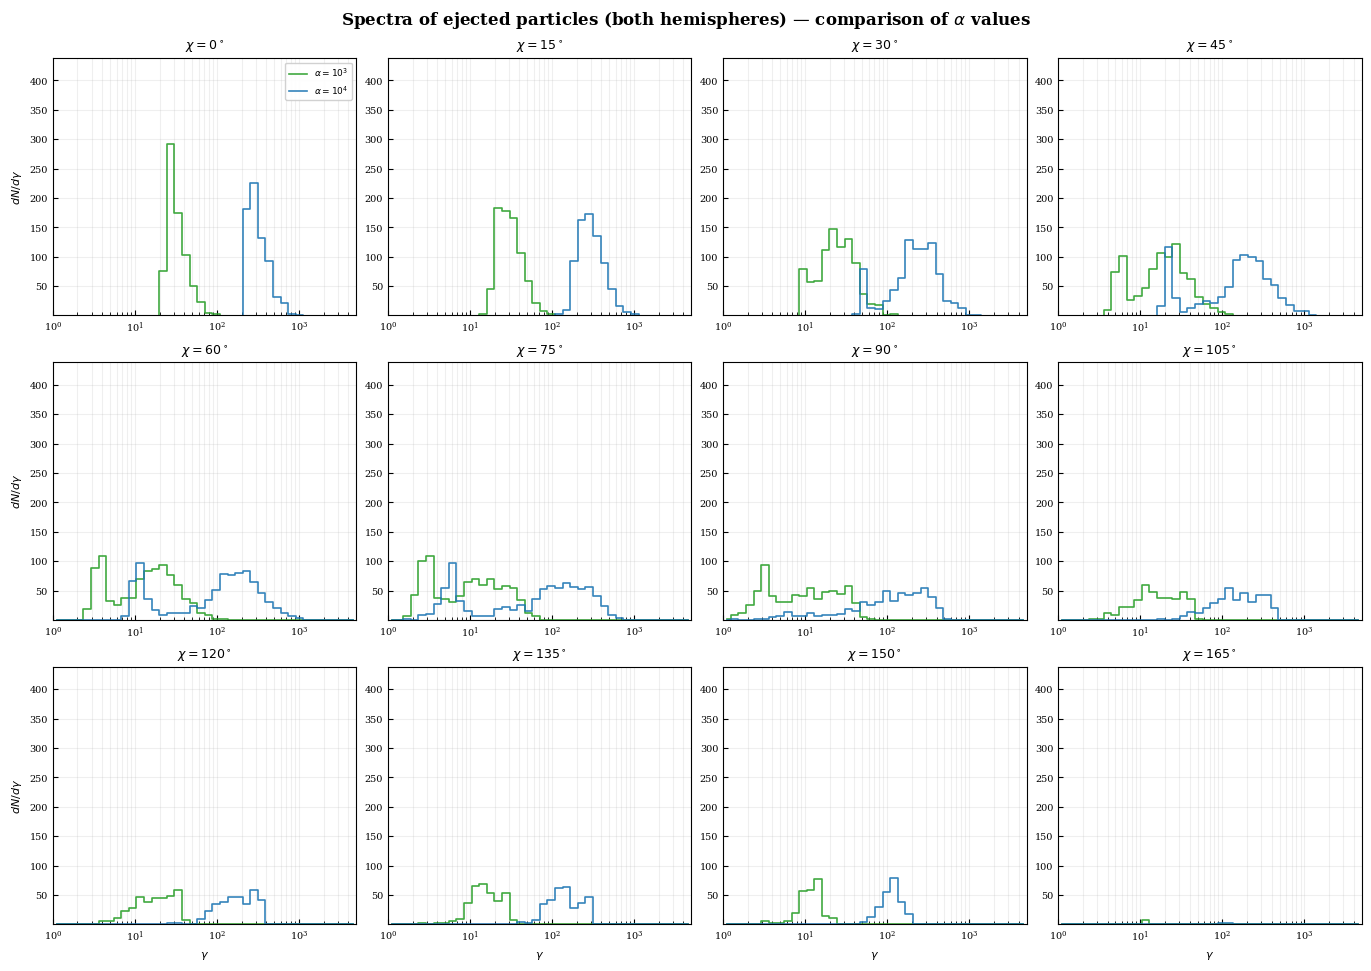

NameError: name 'out_png' is not defined

In [6]:
# ==========================================
# GRADE 3×4 — ESPECTROS SOBREPOSTOS (a partir do CSV)
# Personalizável: ALPHAS, HEMISPHERE
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 8,
    'font.family': 'serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
})

# ==========================================
# CONFIGURAÇÃO — EDITE AQUI
# ==========================================
CSV_FILE     = "particles_all_runs.csv"
ALPHAS       = [1000, 10000]   # qualquer subconjunto presente no CSV
HEMISPHERE   = "both"                     # "N" (z0>0), "S" (z0<0), "both"
ANGLES       = [0, 15, 30, 45, 60, 75,
                90, 105, 120, 135, 150, 165]

N_BINS       = 40
G_LO, G_HI   = 1.0, 5000.0

# Mapa de cores: escolhe automaticamente até 6 cores distintas
_COLOR_POOL = ['tab:green', 'tab:blue', 'tab:red',
               'tab:orange', 'tab:purple', 'tab:brown']
COLORS = {a: _COLOR_POOL[i % len(_COLOR_POOL)] for i, a in enumerate(ALPHAS)}

# ==========================================
# CARREGA CSV E FILTRA
# ==========================================
df = pd.read_csv(CSV_FILE)

# filtra alpha
df = df[df.alpha.isin(ALPHAS)]

# filtra hemisfério
if HEMISPHERE == "N":
    df = df[df.z0 > 0]
elif HEMISPHERE == "S":
    df = df[df.z0 < 0]
# "both" não filtra

# só ejetadas
df_ej = df[df.status == "Ejected"]

# ==========================================
# BINS COMUNS (log)
# ==========================================
LOG_EDGES = np.linspace(np.log10(G_LO), np.log10(G_HI), N_BINS + 1)
G_CENTERS = 10 ** (0.5 * (LOG_EDGES[:-1] + LOG_EDGES[1:]))

# ==========================================
# LAYOUT 3×4
# ==========================================
N_ROWS = 3
N_COLS = 4

fig, axes = plt.subplots(N_ROWS, N_COLS,
                          figsize=(3.4 * N_COLS, 3.2 * N_ROWS),
                          constrained_layout=True)
axes = axes.ravel()

# ---------- Passo 1: histogramas ----------
hists = {a: {} for a in ALPHAS}
for ang in ANGLES:
    for a in ALPHAS:
        d = df_ej[(df_ej.angle_deg == ang) & (df_ej.alpha == a)]
        if len(d) == 0:
            hists[a][ang] = None
            continue
        g = d.gamma_final.values
        g_in = g[(g >= G_LO) & (g <= G_HI)]
        if len(g_in) == 0:
            hists[a][ang] = None
            continue
        hist, _ = np.histogram(np.log10(np.clip(g_in, 1.0, None)),
                               bins=LOG_EDGES)
        hists[a][ang] = hist

# ---------- Passo 2: ylim comum ----------
all_max = 1.0
for a in ALPHAS:
    for h in hists[a].values():
        if h is not None and h.max() > all_max:
            all_max = h.max()
Y_LO = 0.5
Y_HI = max(2.0, all_max * 1.5)

# ---------- Passo 3: plotar ----------
for idx, ang in enumerate(ANGLES):
    ax = axes[idx]
    has_any = False
    for a in ALPHAS:
        hist = hists[a].get(ang)
        if hist is None:
            continue
        has_any = True
        exp = int(round(np.log10(a)))
        # rótulo: se for potência exata de 10, usa notação científica; senão, número
        if 10**exp == a:
            label = rf'$\alpha = 10^{{{exp}}}$'
        else:
            label = rf'$\alpha = {a}$'
        ax.step(G_CENTERS, hist, where='mid',
                color=COLORS[a], lw=1.2, alpha=0.9, label=label)

    if not has_any:
        ax.text(0.5, 0.5, "No data",
                ha='center', va='center', transform=ax.transAxes,
                fontsize=8, color='red')
        ax.set_axis_off()
        continue

    ax.set_xscale('log')
    ax.set_xlim(G_LO, G_HI)
    ax.set_ylim(Y_LO, Y_HI)

    ax.set_title(rf'$\chi = {ang}^\circ$',
                 fontweight='bold', fontsize=9)

    if idx % N_COLS == 0:
        ax.set_ylabel(r'$dN/d\gamma$', fontsize=8)
    if idx >= (N_ROWS - 1) * N_COLS:
        ax.set_xlabel(r'$\gamma$', fontsize=8)

    ax.grid(True, alpha=0.2, which='both')
    ax.tick_params(labelsize=7)

    if idx == 0:
        ax.legend(loc='upper right', fontsize=6.5, framealpha=0.9)

# Título e nome do arquivo incluem hemisfério
hemi_label = {"N": "northern hemisphere",
              "S": "southern hemisphere",
              "both": "both hemispheres"}[HEMISPHERE]
fig.suptitle(rf'Spectra of ejected particles ({hemi_label}) — '
             rf'comparison of $\alpha$ values',
             fontsize=12, fontweight='bold')

out_pdf = f'spectra_comparison_{HEMISPHERE}.pdf'
plt.savefig(out_pdf, bbox_inches='tight', pad_inches=0.05)
plt.show()
print(f"Salvo: {out_pdf}, {out_png}")

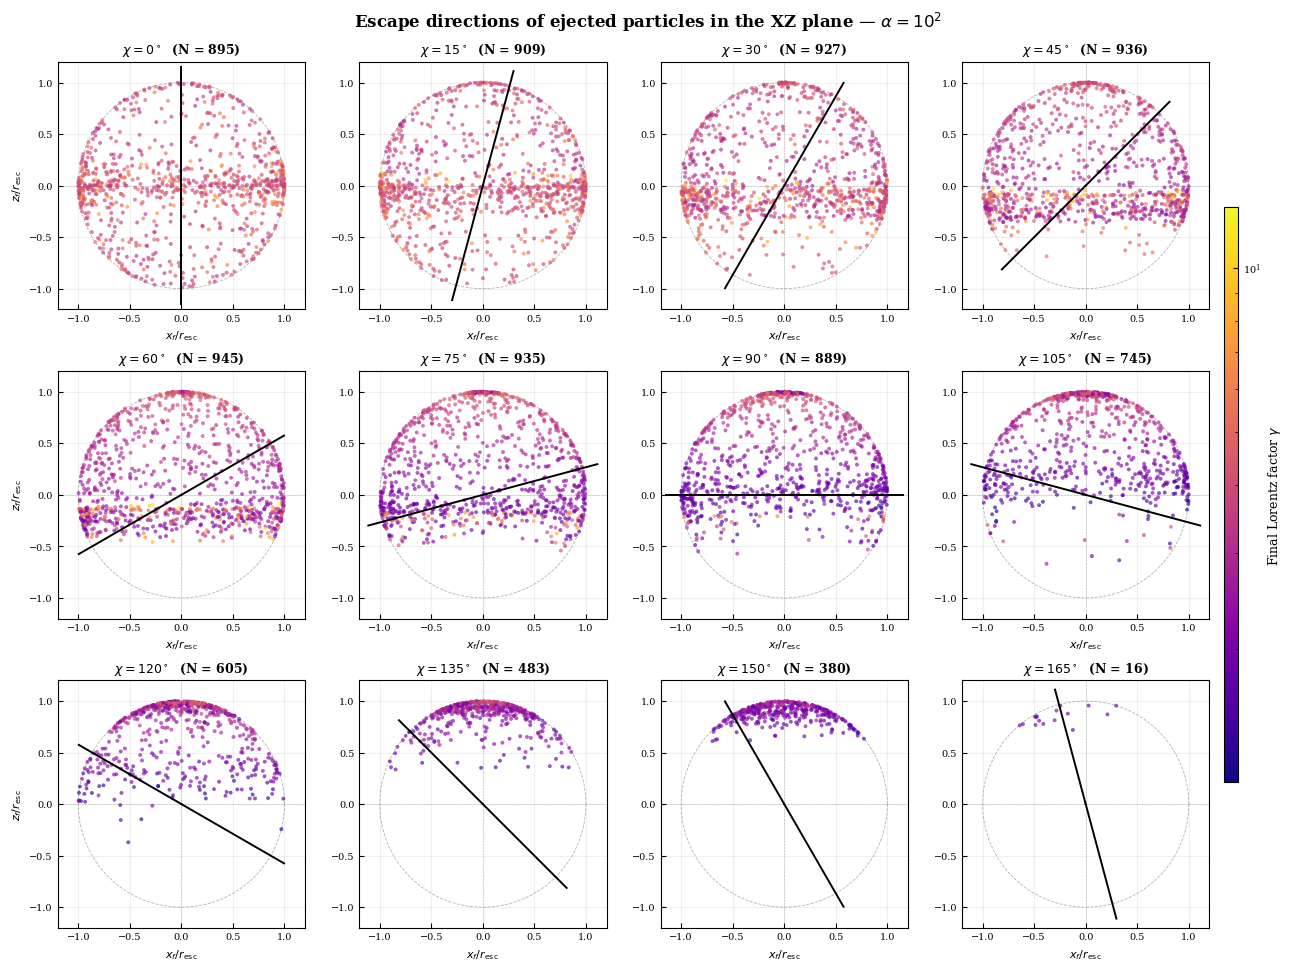

In [18]:
# ==========================================
# GRADE 3×4 — DIREÇÕES FINAIS DE ESCAPE (a partir do CSV)
# α fixo, 12 ângulos, cor = gamma final
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 8,
    'font.family': 'serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
})

# ==========================================
# CONFIGURAÇÃO
# ==========================================
CSV_FILE  = "particles_all_runs.csv"
ALPHA_VAL = 100
ANGLES    = [0, 15, 30, 45, 60, 75,
             90, 105, 120, 135, 150, 165]

POINT_SIZE   = 8
POINT_ALPHA  = 0.65
CMAP         = 'plasma'
MARKER_EDGE  = 'none'

# ==========================================
# CARREGA CSV
# ==========================================
df = pd.read_csv(CSV_FILE)
df_alpha = df[(df.alpha == ALPHA_VAL) & (df.status == "Ejected")].copy()

# Limites globais de gamma para colorbar consistente
if len(df_alpha):
    vmin = max(df_alpha.gamma_final.min(), 1.0)
    vmax = max(df_alpha.gamma_final.max(), vmin * 1.001)
else:
    vmin, vmax = 1.0, 1000.0

# ==========================================
# LAYOUT 3×4
# ==========================================
N_ROWS = 3
N_COLS = 4

fig, axes = plt.subplots(N_ROWS, N_COLS,
                          figsize=(3.2 * N_COLS, 3.2 * N_ROWS),
                          constrained_layout=True)
axes = axes.ravel()

for idx, ang in enumerate(ANGLES):
    ax = axes[idx]
    d = df_alpha[df_alpha.angle_deg == ang]

    if len(d) == 0:
        ax.text(0.5, 0.5, f"No ejected\n$\\chi={ang}^\\circ$",
                ha='center', va='center', transform=ax.transAxes,
                fontsize=8)
        ax.set_axis_off()
        continue

    # Direções finais normalizadas (unidade: esfera)
    r_norm = np.sqrt(d.xf**2 + d.yf**2 + d.zf**2)
    xf_n = d.xf / r_norm
    zf_n = d.zf / r_norm

    # Scatter em XZ, cor = gamma_final
    ax.scatter(xf_n, zf_n,
               c=d.gamma_final.values,
               cmap=CMAP, norm=LogNorm(vmin=vmin, vmax=vmax),
               s=POINT_SIZE, alpha=POINT_ALPHA,
               edgecolors=MARKER_EDGE, linewidths=0, zorder=3)

    # Círculo unitário (esfera de escape normalizada)
    theta_circ = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(theta_circ), np.sin(theta_circ),
            color='gray', lw=0.6, ls='--', alpha=0.6, zorder=2)

    # Eixo magnético (direção (sin χ, cos χ) em XZ)
    chi_rad = np.radians(ang)
    L = 1.15
    ax.plot([0,  L*np.sin(chi_rad)], [0,  L*np.cos(chi_rad)],
            'k-', lw=1.4, zorder=4)
    ax.plot([0, -L*np.sin(chi_rad)], [0, -L*np.cos(chi_rad)],
            'k-', lw=1.4, zorder=4)

    # Linhas guia (equador e eixo de rotação)
    ax.axhline(0, color='k', lw=0.4, ls=':', alpha=0.5, zorder=1)
    ax.axvline(0, color='k', lw=0.4, ls=':', alpha=0.5, zorder=1)

    # Estética
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect('equal')
    ax.set_xlabel(r'$x_f / r_{\rm esc}$', fontsize=8)
    if idx % N_COLS == 0:
        ax.set_ylabel(r'$z_f / r_{\rm esc}$', fontsize=8)
    ax.set_title(rf'$\chi = {ang}^\circ$  (N = {len(d)})',
                 fontweight='bold', fontsize=9)
    ax.grid(True, alpha=0.2, zorder=0)
    ax.tick_params(labelsize=7)

# Colorbar
sm = plt.cm.ScalarMappable(cmap=CMAP,
                           norm=LogNorm(vmin=vmin, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.tolist(), location='right',
                    fraction=0.012, pad=0.012, aspect=40)
cbar.set_label(r'Final Lorentz factor $\gamma$', fontsize=9)

fig.suptitle(r'Escape directions of ejected particles in the XZ plane — '
             rf'$\alpha = 10^{{{int(np.log10(ALPHA_VAL))}}}$',
             fontsize=12, fontweight='bold')

plt.savefig(f'escape_directions_alpha{ALPHA_VAL}.pdf',
            dpi=300, bbox_inches='tight', pad_inches=0.05)
plt.show()

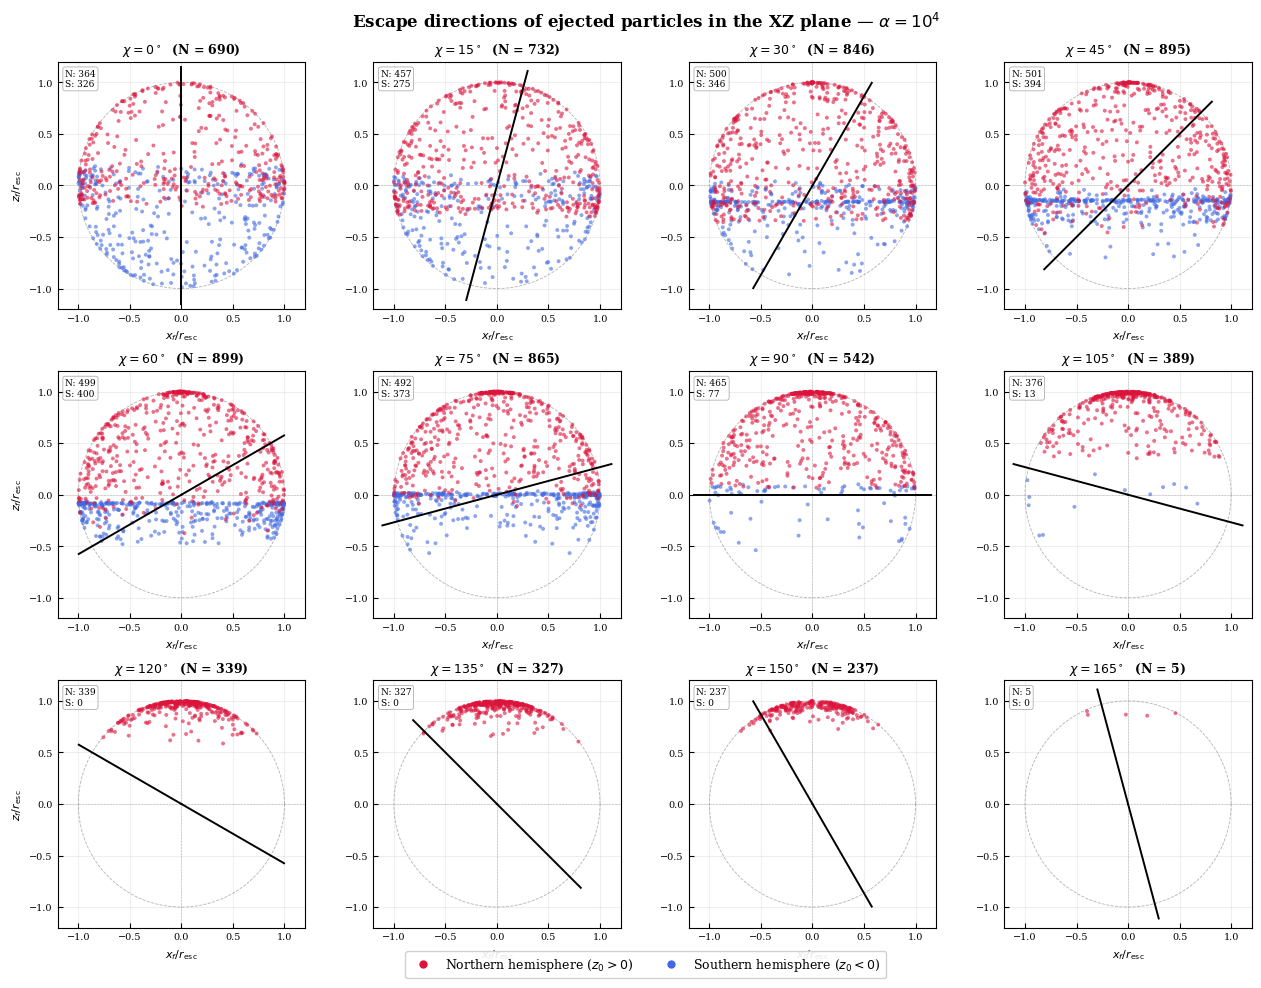

In [ ]:
# ==========================================
# GRADE 3×4 — DIREÇÕES FINAIS DE ESCAPE (a partir do CSV)
# Cor = hemisfério de origem (N=vermelho, S=azul)
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 8,
    'font.family': 'serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
})

# ==========================================
# CONFIGURAÇÃO
# ==========================================
CSV_FILE  = "particles_all_runs.csv"
ALPHA_VAL = 10000
ANGLES    = [0, 15, 30, 45, 60, 75,
             90, 105, 120, 135, 150, 165]

POINT_SIZE   = 8
POINT_ALPHA  = 0.6
MARKER_EDGE  = 'none'

COLOR_N = 'crimson'     # norte
COLOR_S = 'royalblue'   # sul

# ==========================================
# CARREGA CSV
# ==========================================
df = pd.read_csv(CSV_FILE)
df_alpha = df[(df.alpha == ALPHA_VAL) & (df.status == "Ejected")].copy()

# fallback: se a coluna 'hemisphere' não existir, cria a partir de z0
if "hemisphere" not in df_alpha.columns:
    df_alpha["hemisphere"] = np.where(df_alpha.z0 > 0, "N",
                              np.where(df_alpha.z0 < 0, "S", "E"))

# ==========================================
# LAYOUT 3×4
# ==========================================
N_ROWS = 3
N_COLS = 4

fig, axes = plt.subplots(N_ROWS, N_COLS,
                          figsize=(3.2 * N_COLS, 3.2 * N_ROWS),
                          constrained_layout=True)
axes = axes.ravel()

for idx, ang in enumerate(ANGLES):
    ax = axes[idx]
    d = df_alpha[df_alpha.angle_deg == ang]

    if len(d) == 0:
        ax.text(0.5, 0.5, f"No ejected\n$\\chi={ang}^\\circ$",
                ha='center', va='center', transform=ax.transAxes,
                fontsize=8)
        ax.set_axis_off()
        continue

    # Direções finais normalizadas
    r_norm = np.sqrt(d.xf**2 + d.yf**2 + d.zf**2)
    xf_n = (d.xf / r_norm).values
    zf_n = (d.zf / r_norm).values
    hemi = d.hemisphere.values

    mask_N = (hemi == "N")
    mask_S = (hemi == "S")
    n_N = int(mask_N.sum())
    n_S = int(mask_S.sum())

    # Scatter: N em vermelho, S em azul
    ax.scatter(xf_n[mask_S], zf_n[mask_S],
               s=POINT_SIZE, c=COLOR_S, alpha=POINT_ALPHA,
               edgecolors=MARKER_EDGE, linewidths=0, zorder=3)
    ax.scatter(xf_n[mask_N], zf_n[mask_N],
               s=POINT_SIZE, c=COLOR_N, alpha=POINT_ALPHA,
               edgecolors=MARKER_EDGE, linewidths=0, zorder=4)

    # Círculo unitário (esfera de escape normalizada)
    theta_circ = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(theta_circ), np.sin(theta_circ),
            color='gray', lw=0.6, ls='--', alpha=0.6, zorder=2)

    # Eixo magnético (direção (sin χ, cos χ) em XZ)
    chi_rad = np.radians(ang)
    L = 1.15
    ax.plot([0,  L*np.sin(chi_rad)], [0,  L*np.cos(chi_rad)],
            'k-', lw=1.4, zorder=5)
    ax.plot([0, -L*np.sin(chi_rad)], [0, -L*np.cos(chi_rad)],
            'k-', lw=1.4, zorder=5)

    # Linhas guia
    ax.axhline(0, color='k', lw=0.4, ls=':', alpha=0.5, zorder=1)
    ax.axvline(0, color='k', lw=0.4, ls=':', alpha=0.5, zorder=1)

    # Estética
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect('equal')
    ax.set_xlabel(r'$x_f / r_{\rm esc}$', fontsize=8)
    if idx % N_COLS == 0:
        ax.set_ylabel(r'$z_f / r_{\rm esc}$', fontsize=8)
    ax.set_title(rf'$\chi = {ang}^\circ$  (N = {len(d)})',
                 fontweight='bold', fontsize=9)
    ax.grid(True, alpha=0.2, zorder=0)
    ax.tick_params(labelsize=7)

    # Contagem N/S no canto
    ax.text(0.03, 0.97,
            f"N: {n_N}\nS: {n_S}",
            transform=ax.transAxes, ha='left', va='top',
            fontsize=6.5, color='k',
            bbox=dict(boxstyle='round,pad=0.25',
                      facecolor='white', edgecolor='gray',
                      alpha=0.75, linewidth=0.5),
            zorder=6)

# Legenda global (uma vez, no canto inferior)
legend_handles = [
    Line2D([0], [0], marker='o', color='none',
           markerfacecolor=COLOR_N, markeredgecolor='none',
           markersize=6, label='Northern hemisphere ($z_0 > 0$)'),
    Line2D([0], [0], marker='o', color='none',
           markerfacecolor=COLOR_S, markeredgecolor='none',
           markersize=6, label='Southern hemisphere ($z_0 < 0$)'),
]
fig.legend(handles=legend_handles, loc='lower center',
           ncol=2, fontsize=9, frameon=True, framealpha=0.9,
           bbox_to_anchor=(0.5, -0.02))

fig.suptitle(r'Escape directions of ejected particles in the XZ plane — '
             rf'$\alpha = 10^{{{int(np.log10(ALPHA_VAL))}}}$',
             fontsize=12, fontweight='bold')

plt.savefig(f'escape_directions_hemisphere_alpha{ALPHA_VAL}.pdf',
            dpi=300, bbox_inches='tight', pad_inches=0.05)
plt.show()

In [3]:
# =========================================================
# append_alpha.py
# Adiciona incrementalmente os .pkl de um alpha ao CSV
# Rodar várias vezes é seguro: só adiciona o que falta.
# =========================================================
import os
import re
import pickle
import numpy as np
import pandas as pd

# ---------- Configuração ----------
CSV_FILE    = "particles_all_runs.csv"
RESULTS_DIR = "."
ALPHA_NEW   = 100000          # mude conforme o alpha que está rodando
PATTERN     = re.compile(rf"results_angle_(\d+)_alpha{ALPHA_NEW}\.pkl")
STATUSES    = ["Crashed", "Ejected", "Trapped"]

# ---------- Carrega CSV existente ----------
if os.path.isfile(CSV_FILE):
    df_old = pd.read_csv(CSV_FILE)
    print(f"CSV existente: {len(df_old)} linhas")
    print(f"  alphas: {sorted(df_old.alpha.unique())}")
    print(f"  (alpha, angle) já presentes: "
          f"{sorted(df_old[df_old.alpha == ALPHA_NEW].angle_deg.unique())}")
else:
    df_old = pd.DataFrame()
    print(f"CSV não existe ainda; será criado.")

# Ângulos já no CSV para esse alpha
if len(df_old) and ALPHA_NEW in df_old.alpha.unique():
    angles_done = set(df_old[df_old.alpha == ALPHA_NEW].angle_deg.unique())
else:
    angles_done = set()

# ---------- Encontra os .pkl disponíveis ----------
files = sorted(f for f in os.listdir(RESULTS_DIR) if PATTERN.match(f))
print(f"\nArquivos .pkl para alpha={ALPHA_NEW}: {len(files)}")

records = []
skipped = []
for fname in files:
    m = PATTERN.match(fname)
    angle_deg = int(m.group(1))

    if angle_deg in angles_done:
        skipped.append(angle_deg)
        continue

    fpath = os.path.join(RESULTS_DIR, fname)
    with open(fpath, "rb") as f:
        data = pickle.load(f)

    if not isinstance(data, dict):
        print(f"[skip] formato inesperado: {fname}")
        continue

    # Verifica se o .pkl tem t_final
    has_t = ("t_final" in data.get("Ejected", {}))

    n_this = 0
    for status in STATUSES:
        if status not in data:
            continue
        block = data[status]
        xs   = block.get("x", [])
        ys   = block.get("y", [])
        zs   = block.get("z", [])
        xfs  = block.get("xf", [])
        yfs  = block.get("yf", [])
        zfs  = block.get("zf", [])
        gs   = block.get("gamas", [])
        ts   = block.get("t_final", [np.nan] * len(xs)) if has_t else [np.nan] * len(xs)

        n = len(xs)
        for i in range(n):
            if i < len(ys) and hasattr(ys[i], "__len__") and len(ys[i]) >= 3:
                x0, y0, z0 = float(ys[i][0]), float(ys[i][1]), float(ys[i][2])
            else:
                x0, y0, z0 = float(xs[i]), 0.0, float(zs[i])

            xf = float(xfs[i]) if i < len(xfs) else np.nan
            yf = float(yfs[i]) if i < len(yfs) else np.nan
            zf = float(zfs[i]) if i < len(zfs) else np.nan
            gf = float(gs[i])  if i < len(gs)  else np.nan
            tf = float(ts[i])  if i < len(ts)  else np.nan

            r0 = float(np.sqrt(x0**2 + y0**2 + z0**2))
            cos_t = z0 / r0 if r0 > 0 else np.nan
            theta0 = float(np.degrees(np.arccos(np.clip(cos_t, -1, 1)))) \
                     if np.isfinite(cos_t) else np.nan
            phi0 = float(np.degrees(np.arctan2(y0, x0)))
            rf = float(np.sqrt(xf**2 + yf**2 + zf**2)) \
                 if np.isfinite(xf) else np.nan

            records.append({
                "alpha": ALPHA_NEW,
                "angle_deg": angle_deg,
                "status": status,
                "particle_id_local": i,
                "x0": x0, "y0": y0, "z0": z0,
                "r0": r0,
                "theta0_deg": theta0,
                "phi0_deg": phi0,
                "hemisphere": ("N" if z0 > 0 else ("S" if z0 < 0 else "E")),
                "xf": xf, "yf": yf, "zf": zf, "rf": rf,
                "gamma_final": gf,
                "t_final": tf,
            })
            n_this += 1

    print(f"  [ok] angle={angle_deg:3d}: {n_this} partículas adicionadas")

if skipped:
    print(f"\nÂngulos já presentes (pulados): {sorted(skipped)}")

if not records:
    print("\nNada novo para adicionar. CSV inalterado.")
else:
    df_new = pd.DataFrame.from_records(records)
    df = pd.concat([df_old, df_new], ignore_index=True)

    # Recalcula uid (útil para rastrear partículas entre alphas)
    df["uid"] = (df[["x0","y0","z0"]].round(6).astype(str).agg("|".join, axis=1))

    df.to_csv(CSV_FILE, index=False)
    print(f"\nSalvo: {CSV_FILE}  ({len(df)} linhas no total)")
    print(f"  Linhas adicionadas: {len(df_new)}")
    print(f"  Alphas no CSV: {sorted(df.alpha.unique())}")
    print("\nResumo por (alpha, angle, status):")
    print(df.groupby(["alpha","angle_deg","status"]).size()
            .unstack(fill_value=0))

CSV existente: 43000 linhas
  alphas: [100, 1000, 3000, 10000]
  (alpha, angle) já presentes: []

Arquivos .pkl para alpha=100000: 2
  [ok] angle=  0: 1000 partículas adicionadas
  [ok] angle= 30: 1000 partículas adicionadas

Salvo: particles_all_runs.csv  (45000 linhas no total)
  Linhas adicionadas: 2000
  Alphas no CSV: [100, 1000, 3000, 10000, 100000]

Resumo por (alpha, angle, status):
status            Crashed  Ejected  Trapped
alpha  angle_deg                           
100    0                7      895       98
       15               7      909       84
       30               9      927       64
       45              15      936       49
       60              16      945       39
       75              22      935       43
       90              39      889       72
       105             63      745      192
       120             91      605      304
       135            112      483      405
       150            147      380      473
       165            204       16